# Exercise P8.1: Bootstrap CIs & Multiple Testing
### STAT 540 — Week 8


## Overview

In this exercise, you will construct bootstrap confidence intervals and demonstrate the multiple testing problem.

## Task 1: Bootstrap CI for the Median

Sample median: 2076.98
Bootstrap 95% CI: (1993.56, 2167.31)


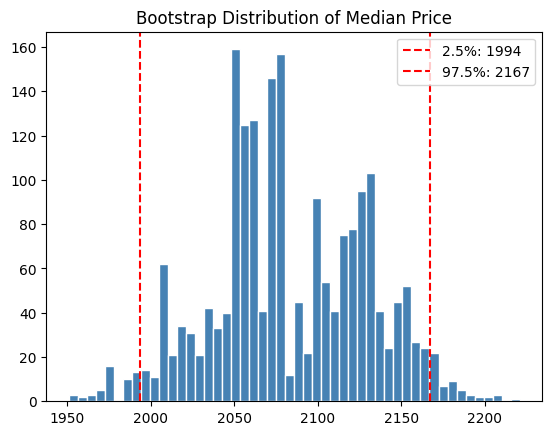

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# Use diamond prices (or load from CSV)
# prices = diamonds["price"].values
prices = rng.exponential(scale=3000, size=5000)   # Simulated if needed

boot_medians = np.array([
    np.median(rng.choice(prices, size=len(prices), replace=True))
    for _ in range(2000)
])

ci = np.percentile(boot_medians, [2.5, 97.5])
print(f"Sample median: {np.median(prices):.2f}")
print(f"Bootstrap 95% CI: ({ci[0]:.2f}, {ci[1]:.2f})")

plt.hist(boot_medians, bins=50, color="steelblue", edgecolor="white")
plt.axvline(ci[0], color="red", linestyle="--", label=f"2.5%: {ci[0]:.0f}")
plt.axvline(ci[1], color="red", linestyle="--", label=f"97.5%: {ci[1]:.0f}")
plt.title("Bootstrap Distribution of Median Price")
plt.legend()
plt.show()

**Your turn:** How does the bootstrap CI compare to the parametric CI for the mean? Which is more appropriate for skewed data and why?

**Answer:**

> I think the bootstrap method is better, but there is a caveat to this. A parametric confidence interval for the mean assumes that the sampling distribution is symmetric and bell-shaped, building an interval of the form $\bar{x} \pm t \cdot s / \sqrt{n}$ that extends equally on both sides. In contrast, the bootstrap method avoids distributional assumptions by resampling the observed dataset with replacement thousands of times, calculating the mean for each trial, and defining the interval directly from the percentiles of those resampled means.

> While both methods align closely when working with symmetric data or large sample sizes, the bootstrap is far more appropriate for skewed data (such as income, response times, or exponential distributions) coupled with modest sample sizes. In these skewed scenarios, the true sampling distribution is asymmetric, causing the symmetric parametric $t$-interval to undercover and typically miss the parameter on the long-tail side; the bootstrap accommodates this by constructing an asymmetric interval that reflects actual reality.

> However, the bootstrap is not perfect, as with tiny samples, it struggles because it cannot account for tail data not present in the original sample, it can struggle with extremely heavy tails, and it still requires independent observations. Thus, for moderately skewed data with a sample size between 30 and a few hundred, the bootstrap is preferred, whereas extreme skewness or very small samples are better handled via transformations, medians, or trimmed means.

In [ ]:
from scipy import stats
import numpy as np

rng = np.random.default_rng(0)

# Run 20 t-tests on RANDOM data — no true effects
p_values = [
    stats.ttest_ind(rng.normal(size=50), rng.normal(size=50)).pvalue
    for _ in range(20)
]

print(f"Tests run: 20")
print(f"Significant at p < 0.05: {sum(p < 0.05 for p in p_values)}")
print(f"Expected by chance: {20 * 0.05}")

# Apply Bonferroni
bonf_sig = sum(p < 0.05/20 for p in p_values)
print(f"Significant after Bonferroni: {bonf_sig}")

Tests run: 20
Significant at p < 0.05: 2
Expected by chance: 1.0
Significant after Bonferroni: 0


**Your turn:** How many false positives did you get? Was this close to the expected number?

I obtained 2 false positives at the $p < 0.05$ threshold. This is very close to the expected value of 1 false positive ($20 \times 0.05 = 1$) that was anticipated getting by pure chance.

In [ ]:
from statsmodels.stats.multitest import multipletests

rejected_bonf, p_bonf, _, _ = multipletests(p_values, method="bonferroni")
rejected_fdr, p_fdr, _, _ = multipletests(p_values, method="fdr_bh")

print(f"Bonferroni rejections: {sum(rejected_bonf)}")
print(f"FDR rejections: {sum(rejected_fdr)}")

Bonferroni rejections: 0
FDR rejections: 0


**Your turn:** Explain in your own words the difference between Bonferroni and FDR correction:

> The difference between the two approaches lies in what type of error they attempt to control. The Bonferroni correction controls the Family-Wise Error Rate (FWER), which is the probability of making at least one false positive (Type I error) across all tests, by applying a highly conservative significance threshold of $\alpha / m$$\alpha / m$. While this strictly prevents false positives, it severely reduces statistical power and increases false negatives. Conversely, the False Discovery Rate (FDR) correction, such as the Benjamini-Hochberg procedure, controls the expected proportion of false positives among only the declared significant results. For instance, setting an FDR threshold of $0.05$$0.05$ means that we accept that roughly 5% of our discoveries will be false positives in exchange for gaining significantly higher statistical power. This makes FDR far more appropriate for high-throughput exploratory analyses where discovering potential leads is more valuable than completely eliminating all false positives.

## Task 4: Reflection

In 100–150 words, reflect on the implications of the multiple testing problem for data science practice. When should you apply corrections? When might you skip them?

> In data science, multiple testing corrections are crucial when making high-stakes decisions or confirmatory claims, such as clinical trials or public policy changes, where a single false positive could lead to costly or harmful actions. In these scenarios, controlling the Family-Wise Error Rate (FWER) using Bonferroni or False Discovery Rate (FDR) using Benjamini-Hochberg is essential to maintain statistical integrity.
>  
> Conversely, you might choose to skip or relax corrections during exploratory EDA, early-stage feature selection, or hypothesis-generation phases. When searching for potential leads in massive datasets, the cost of a false negative (missing a true, valuable signal) is often much higher than the cost of a false positive, which can be filtered out in follow-up validation experiments. Skipping corrections in these initial exploratory stages prevents the loss of statistical power, allowing promising patterns to be surfaced for subsequent, dedicated testing.

## Submission

```bash
git add week08/exercises/P8.1*
git commit -m "Complete Exercise P8.1: Bootstrap CIs and multiple testing"
git push origin main
```